**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import sys
import subprocess
import importlib.util

packages = {
    "kagglehub": "kagglehub",
    "prophet": "prophet",
    "tensorflow": "tensorflow",
    "statsmodels": "statsmodels"
}

for package, module in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", package
        ])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
# Завантажте датасет з Kaggle
from pathlib import Path
import kagglehub

csv_path = Path("kaggel_weather_2013_to_2024.csv")

if not csv_path.exists():
    folder = Path(kagglehub.dataset_download(
        "yug201/daily-climate-time-series-data-delhi-india"
    ))

    csv_files = list(folder.rglob("*.csv"))

    csv_path = next(
        (p for p in csv_files
         if p.name == "kaggel_weather_2013_to_2024.csv"),
        csv_files[0]
    )

print("Файл:", csv_path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Файл: /kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(csv_path)

display(df.head())
print("Розмір:", df.shape)
print("Стовпці:", df.columns.tolist())

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Розмір: (3557, 29)
Стовпці: ['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
date_col = next(
    c for c in df.columns
    if c.strip().lower() in ["date", "datetime"]
)

temp_col = next(
    c for c in df.columns
    if "temp" in c.lower() or c.lower() == "tavg"
)

df[date_col] = pd.to_datetime(df[date_col])

df = df.sort_values(date_col)
df = df.drop_duplicates(subset=[date_col])
df = df.set_index(date_col)

df = df[[temp_col]].rename(
    columns={temp_col: "temperature"}
)

df["temperature"] = pd.to_numeric(
    df["temperature"], errors="coerce"
)

df = df.asfreq("D")

display(df.head())

,temperature
DATE,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()
display(df.describe())
print("Розмір:", df.shape)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  3556 non-null   float64
dtypes: float64(1)
memory usage: 66.4 KB


,temperature
count,3556.000000
mean,31.365073
std,7.073447
min,9.100000
25%,26.400000
50%,32.950000
75%,36.000000
max,47.900000


Розмір: (4249, 1)


In [6]:
# Перевірте наявність пропущених значень
print("Пропущені значення до обробки:")
print(df.isnull().sum())

df["temperature"] = (
    df["temperature"]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

print("\nПісля обробки:")
print(df.isnull().sum())

Пропущені значення до обробки:
temperature    693
dtype: int64

Після обробки:
temperature    0
dtype: int64


Графік температури

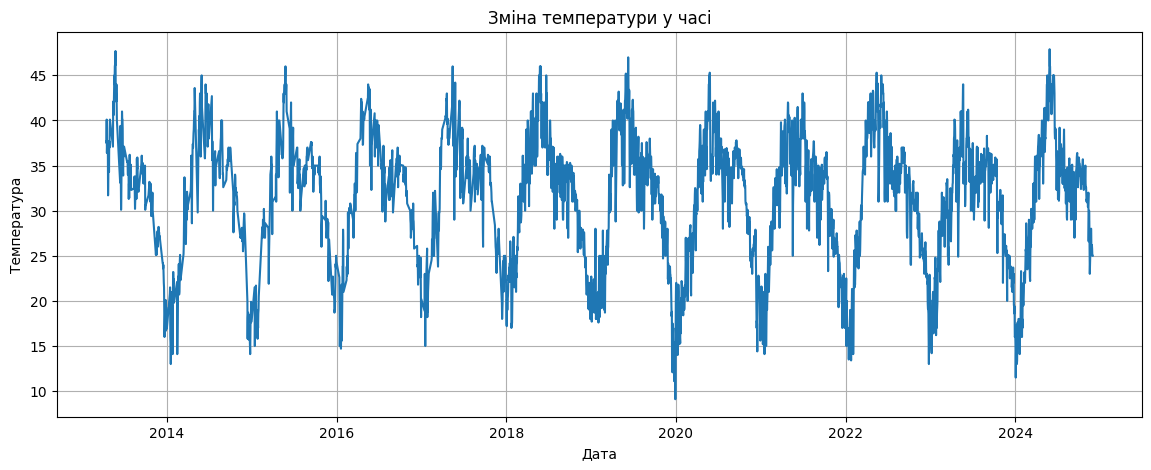

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["temperature"])

plt.title("Зміна температури у часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.grid(True)
plt.show()

Ковзне середнє

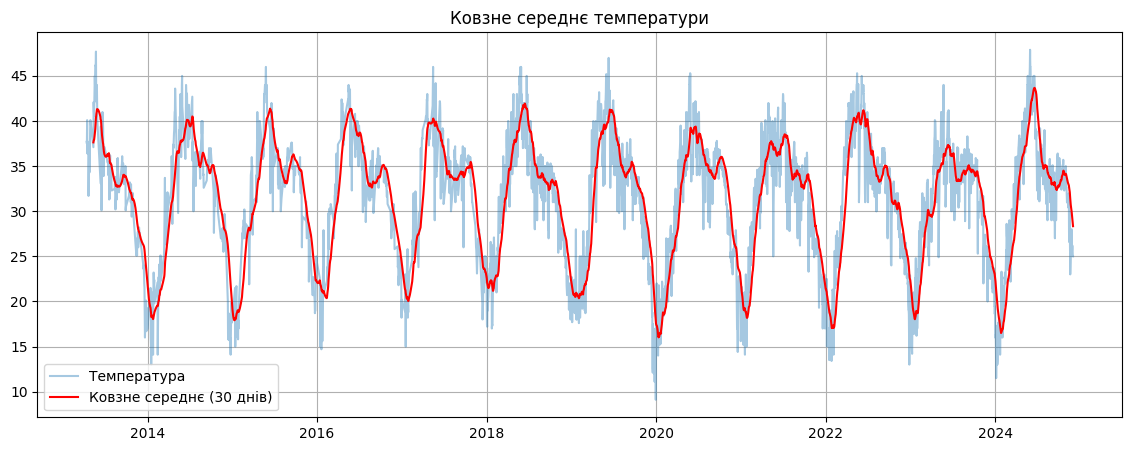

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["rolling_mean_30"] = (
    df["temperature"].rolling(window=30).mean()
)

plt.figure(figsize=(14, 5))

plt.plot(df.index, df["temperature"],
         alpha=0.4, label="Температура")

plt.plot(df.index, df["rolling_mean_30"],
         color="red", label="Ковзне середнє (30 днів)")

plt.legend()
plt.title("Ковзне середнє температури")
plt.grid(True)
plt.show()

Розподіл температури

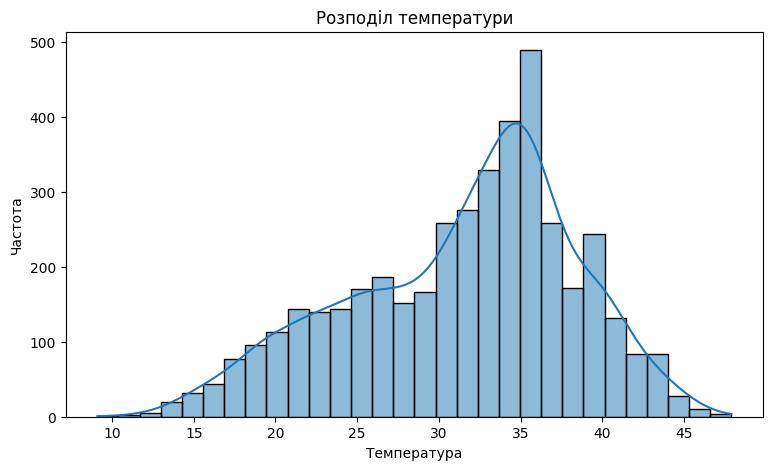

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(9, 5))

sns.histplot(df["temperature"], bins=30, kde=True)

plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.show()

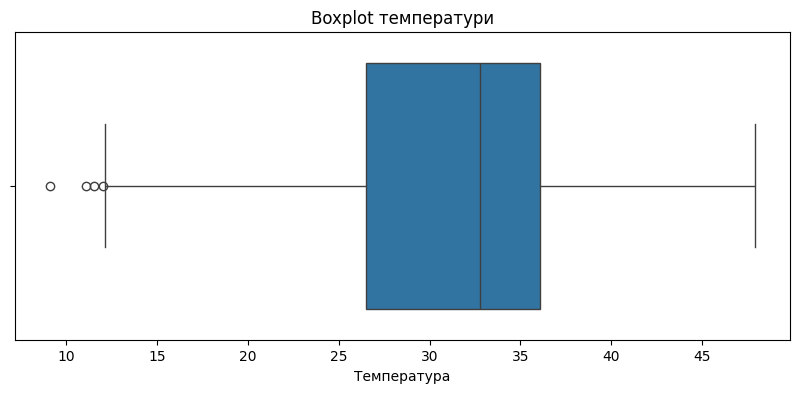

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["temperature"])

plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.show()

Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

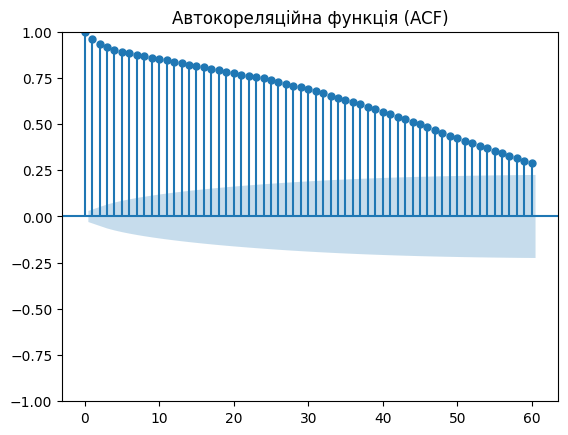

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
plt.figure(figsize=(12, 5))

plot_acf(df["temperature"], lags=60)
plt.title("Автокореляційна функція (ACF)")
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

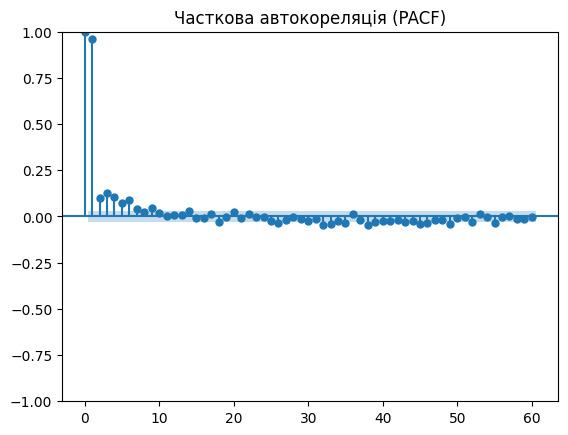

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 5))

plot_pacf(df["temperature"], lags=60, method="ywm")
plt.title("Часткова автокореляція (PACF)")
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Train: 3399
Test: 850


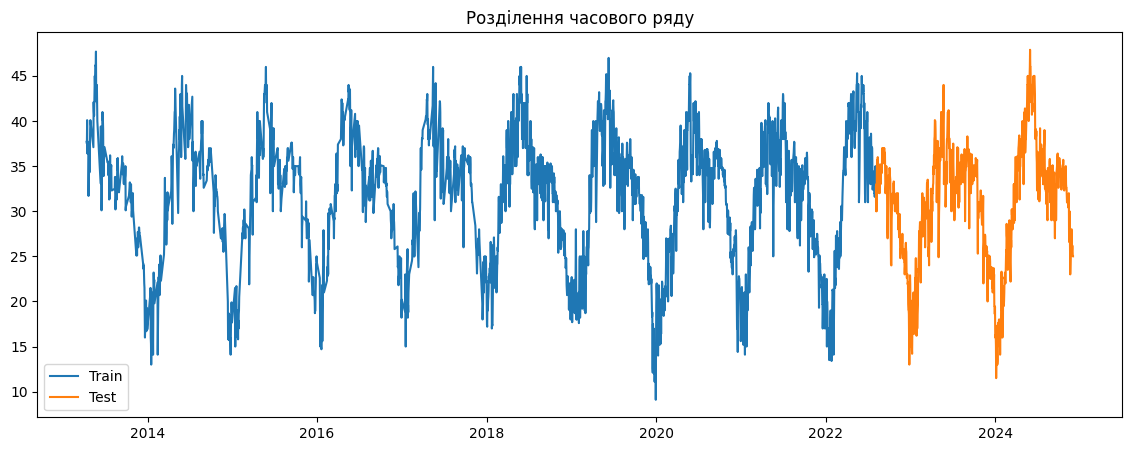

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
series = df["temperature"].astype(float)

split_index = int(len(series) * 0.8)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Train:", len(train))
print("Test:", len(test))

plt.figure(figsize=(14, 5))
plt.plot(train, label="Train")
plt.plot(test, label="Test")
plt.legend()
plt.title("Розділення часового ряду")
plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(train, order=(3, 1, 1))

arima_fit = arima_model.fit()

arima_pred = pd.Series(
    arima_fit.forecast(steps=len(test)).to_numpy(),
    index=test.index,
    name="ARIMA"
)

print(arima_pred.head())

DATE
2022-08-04    33.747113
2022-08-05    33.658227
2022-08-06    33.624084
2022-08-07    33.610007
2022-08-08    33.603982
Freq: D, Name: ARIMA, dtype: float64


In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            temperature   No. Observations:                 3399
Model:                 ARIMA(3, 1, 1)   Log Likelihood               -6834.836
Date:                Wed, 28 Oct 2026   AIC                          13679.673
Time:                        15:44:15   BIC                          13710.327
Sample:                    04-14-2013   HQIC                         13690.629
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6159      0.038     16.248      0.000       0.542       0.690
ar.L2         -0.0698      0.018     -3.827      0.000      -0.106      -0.034
ar.L3         -0.0029      0.020     -0.147      0.8

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

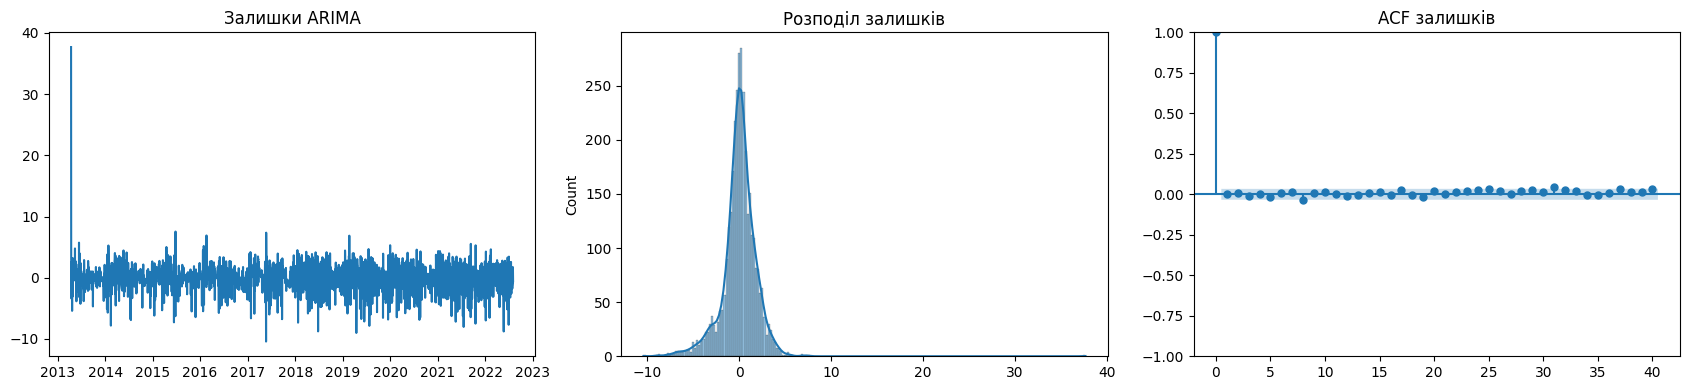

In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_fit.resid.dropna()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(residuals)
axes[0].set_title("Залишки ARIMA")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Розподіл залишків")

plot_acf(residuals, lags=40, ax=axes[2])
axes[2].set_title("ACF залишків")

plt.tight_layout()
plt.show()

In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    mask = np.abs(actual) > 1e-8

    mape = (
        np.mean(
            np.abs((actual[mask] - predicted[mask]) /
                   actual[mask])
        ) * 100
        if mask.any() else np.nan
    )

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}


arima_metrics = calculate_metrics(test, arima_pred)

print("ARIMA:")
print(arima_metrics)

ARIMA:
{'MAE': 5.234359443949144, 'RMSE': np.float64(7.087635219723988), 'MAPE (%)': np.float64(21.52106865511116)}


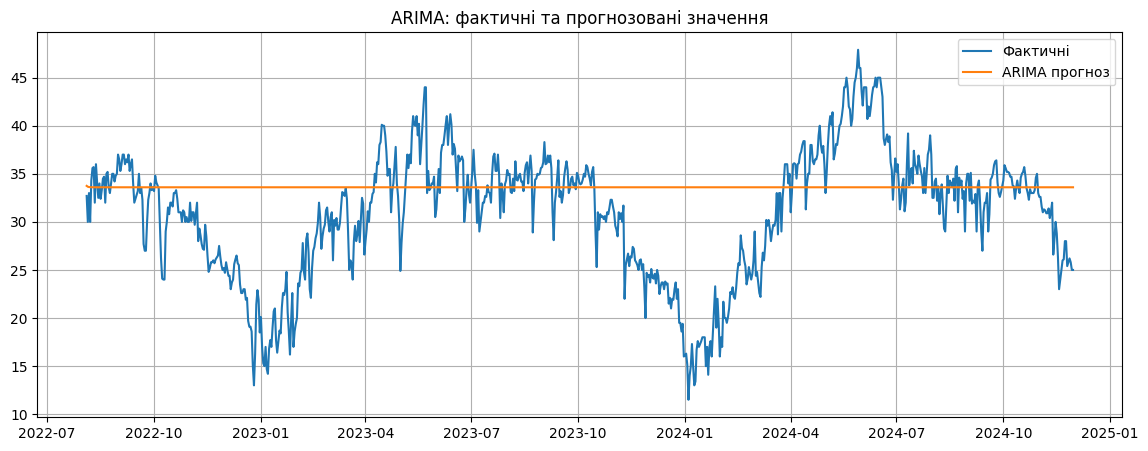

In [18]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Фактичні")
plt.plot(test.index, arima_pred, label="ARIMA прогноз")

plt.title("ARIMA: фактичні та прогнозовані значення")
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = pd.DataFrame({
    "ds": train.index,
    "y": train.values
})

display(prophet_train.head())

,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [20]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

Прогноз

In [21]:
# Побудуйте прогноз Prophet для тестового періоду
future = pd.DataFrame({
    "ds": test.index
})

prophet_forecast = prophet_model.predict(future)

prophet_pred = pd.Series(
    prophet_forecast["yhat"].values,
    index=test.index,
    name="Prophet"
)

display(prophet_forecast[["ds", "yhat"]].head())

,ds,yhat
0,2022-08-04,33.937177
1,2022-08-05,33.971244
2,2022-08-06,33.964500
3,2022-08-07,34.120878
4,2022-08-08,34.224307


In [22]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_metrics = calculate_metrics(test, prophet_pred)

print("Prophet:")
print(prophet_metrics)

Prophet:
{'MAE': 2.4871649480698417, 'RMSE': np.float64(3.2635129373768397), 'MAPE (%)': np.float64(8.999084992813021)}


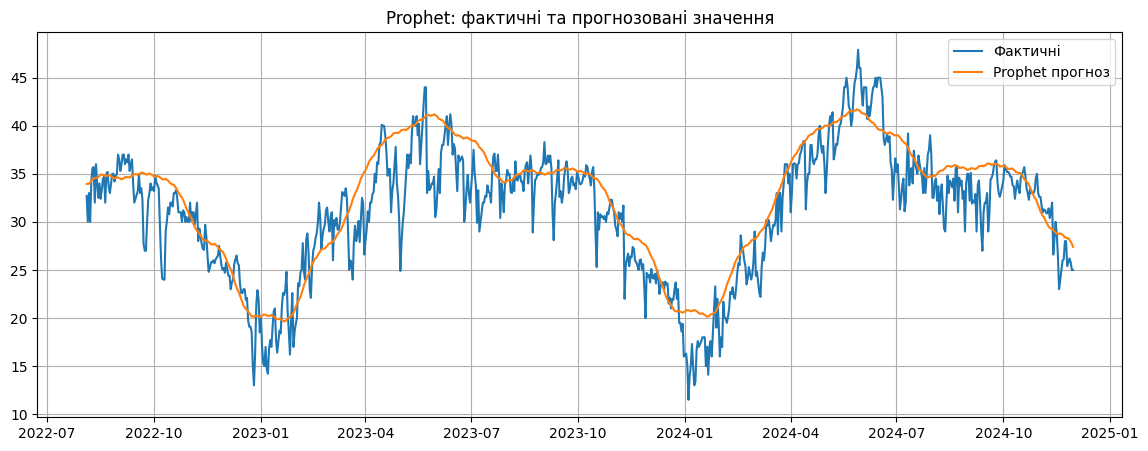

In [23]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Фактичні")
plt.plot(test.index, prophet_pred, label="Prophet прогноз")

plt.title("Prophet: фактичні та прогнозовані значення")
plt.legend()
plt.grid(True)
plt.show()

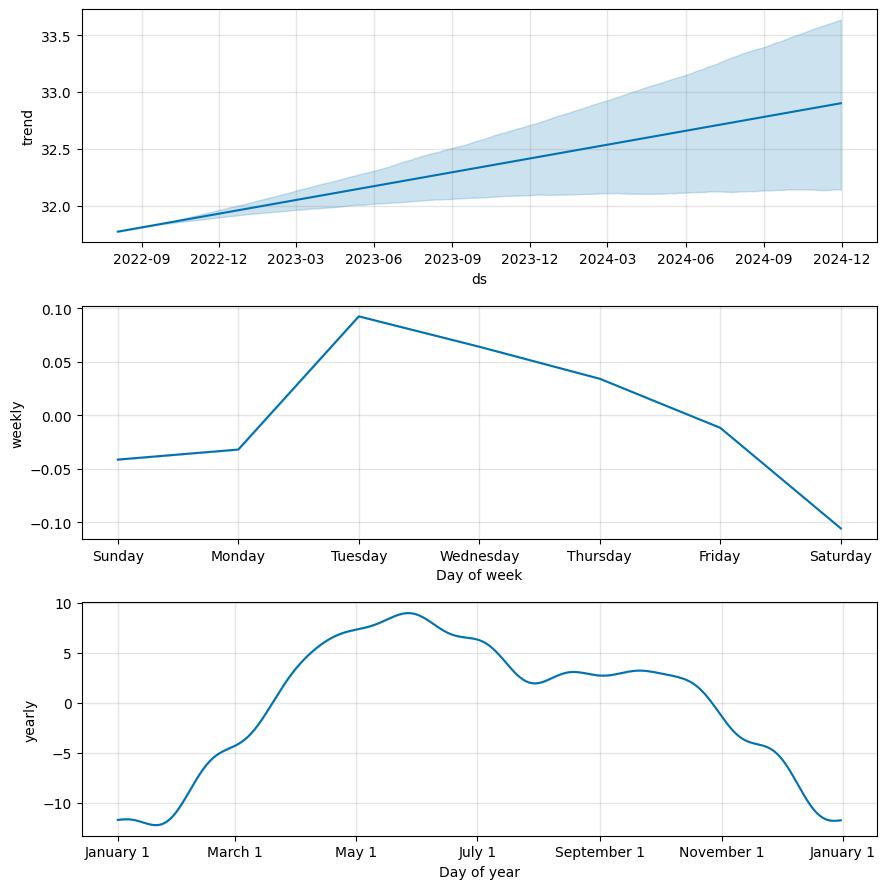

In [24]:
# Побудуйте компоненти моделі Prophet
fig = prophet_model.plot_components(prophet_forecast)

plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train.values.reshape(-1, 1)
)

test_scaled = scaler.transform(
    test.values.reshape(-1, 1)
)

look_back = 30

def create_sequences(data, window=30):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)

In [26]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
X_train_lstm, y_train_lstm = create_sequences(
    train_scaled, look_back
)

test_context = np.concatenate([
    train_scaled[-look_back:],
    test_scaled
])

X_test_lstm, y_test_lstm = create_sequences(
    test_context, look_back
)

print("X_train:", X_train_lstm.shape)
print("X_test:", X_test_lstm.shape)

X_train: (3369, 30, 1)
X_test: (850, 30, 1)


In [27]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(32),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

In [28]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0323 - val_loss: 0.0057
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0044 - val_loss: 0.0047
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0039 - val_loss: 0.0044
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0038 - val_loss: 0.0043
Epoch 5/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0037 - val_loss: 0.0042
Epoch 6/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036 - val_loss: 0.0041
Epoch 7/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0035 - val_loss: 0.0040
Epoch 8/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0034 - val_loss: 0.0040
Epoch 9/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0034 - val_loss: 0.0039
Epoch 10/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0033 - val_loss: 0.0038
Epoch 11/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - val_loss: 0.0037
Epoch 12/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - val_

In [29]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,157 (51.40 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,772 (34.27 KB)

In [30]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
window = train_scaled[-look_back:].reshape(1, look_back, 1)
future_scaled = []

for _ in range(len(test)):
    value = float(
        lstm_model(window, training=False).numpy()[0, 0]
    )

    future_scaled.append(value)

    window = np.concatenate([
        window[:, 1:, :],
        np.array(value).reshape(1, 1, 1)
    ], axis=1)

lstm_pred_values = scaler.inverse_transform(
    np.array(future_scaled).reshape(-1, 1)
).ravel()

print(lstm_pred_values[:10])

[33.56304302 33.58624828 33.61080177 33.62774901 33.6389099  33.64581212
 33.64971647 33.65156627 33.6516537  33.65067128]


In [31]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_dates = test.index

lstm_pred = pd.Series(
    lstm_pred_values,
    index=lstm_dates,
    name="LSTM"
)

display(lstm_pred.head())

,LSTM
DATE,
2022-08-04,33.563043
2022-08-05,33.586248
2022-08-06,33.610802
2022-08-07,33.627749
2022-08-08,33.638910


In [32]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_metrics = calculate_metrics(test, lstm_pred)

print("LSTM:")
print(lstm_metrics)

LSTM:
{'MAE': 5.167315568966025, 'RMSE': np.float64(6.87844647413888), 'MAPE (%)': np.float64(20.840386722720883)}


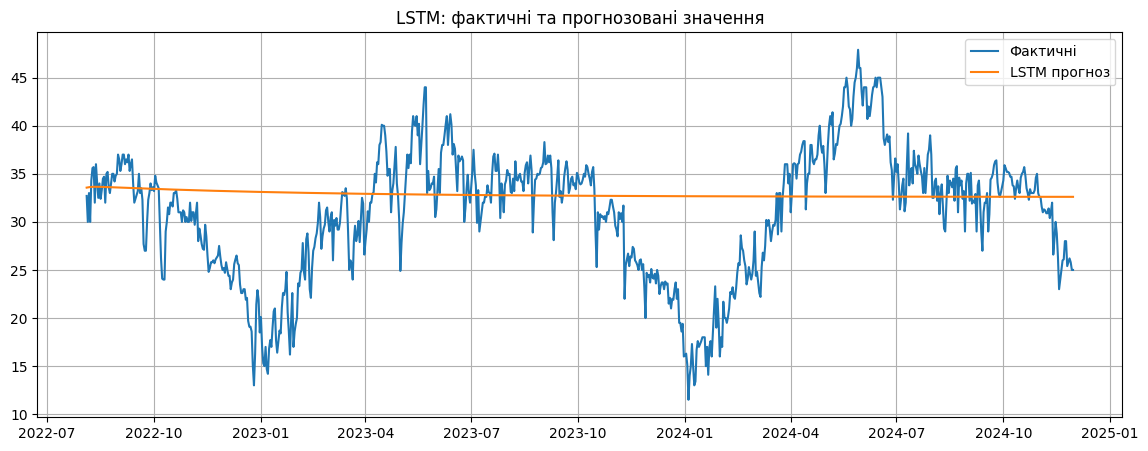

In [33]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Фактичні")
plt.plot(test.index, lstm_pred, label="LSTM прогноз")

plt.title("LSTM: фактичні та прогнозовані значення")
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

Порівняння моделей:


,MAE,RMSE,MAPE (%)
Prophet,2.487,3.264,8.999
LSTM,5.167,6.878,20.840
ARIMA,5.234,7.088,21.521


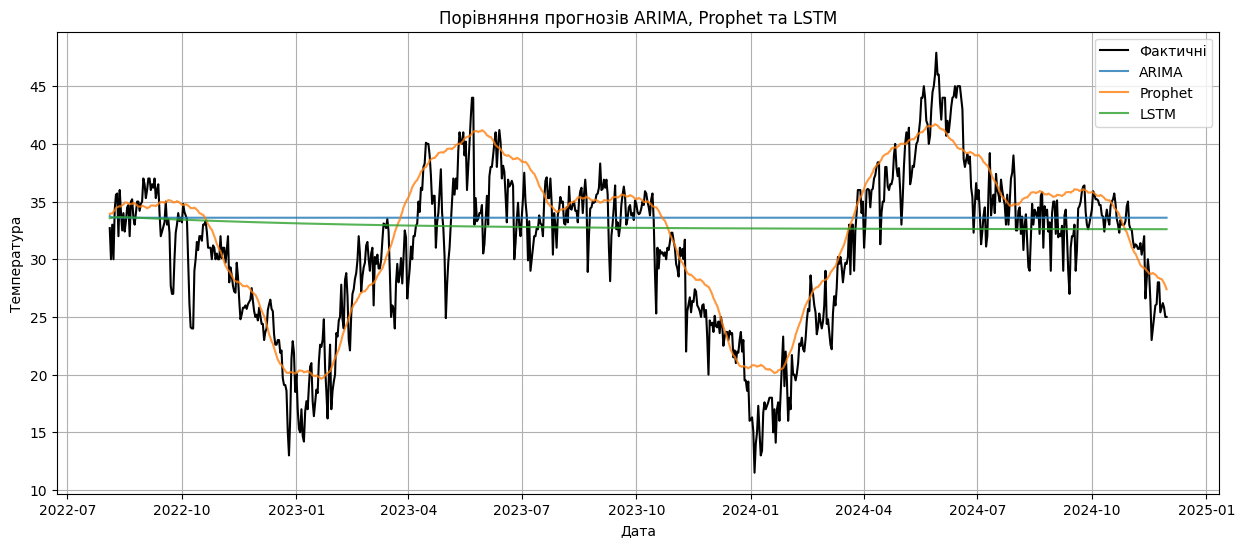


Найкраща модель за MAE: Prophet
MAE: 2.487
RMSE: 3.264
MAPE: 9.0 %


In [34]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "ARIMA": arima_metrics,
    "Prophet": prophet_metrics,
    "LSTM": lstm_metrics
}).T

results = results.sort_values("MAE")

print("Порівняння моделей:")
display(results.round(3))

plt.figure(figsize=(15, 6))

plt.plot(test.index, test,
         label="Фактичні", color="black")

plt.plot(test.index, arima_pred,
         label="ARIMA", alpha=0.8)

plt.plot(test.index, prophet_pred,
         label="Prophet", alpha=0.8)

plt.plot(test.index, lstm_pred,
         label="LSTM", alpha=0.8)

plt.title("Порівняння прогнозів ARIMA, Prophet та LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()

best_model = results["MAE"].idxmin()

print("\nНайкраща модель за MAE:", best_model)
print("MAE:", round(results.loc[best_model, "MAE"], 3))
print("RMSE:", round(results.loc[best_model, "RMSE"], 3))
print("MAPE:", round(results.loc[best_model, "MAPE (%)"], 2), "%")

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.
